# 1 · Data: collection, the evolution of cybersecurity, and the leakage hunt
**Goal of the project:** on the day a CVE is published, rank it by the chance attackers exploit it within 90 days
(= CISA adds it to the **KEV** catalogue within 90 days), so a vulnerability team spends its limited **K emergency
patches a month** where it matters. **Stakeholder:** Head of Vulnerability Management → CISO.
**Current policy (assumed):** emergency-patch every CVE with CVSS ≥ 9 — common severity-based practice, *not verified for
a specific organisation*; notebooks 2–3 therefore compare against several rules and every capacity K.

Notebooks: [1 data](1_data.ipynb) · [2 train & validate](2_train_validate.ipynb) · [3 test](3_test.ipynb) · [4 results for the CISO](4_results_ciso.ipynb) · [5 CISO tool](5_ciso_tool.ipynb) · detailed appendices in `appendix/`.

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "mpl")); os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
TAB, FIG = ROOT / "outputs" / "tables", ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, AQUA, VIOLET, RED, INK, INK2, GRID, SURF = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#d64545", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "font.size": 9.5})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
def T(name, **kw): return pd.read_csv(TAB / f"{name}.csv", **kw)
def save(fig, name): fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
pt = lambda s: float(str(s).split()[0])
HEAD, ALT, EPSS7 = "gradient boosting (headline)", "late fusion (alternative)", 'EPSS (first score, <=7 d after pub)'

## 1.1 Data collection
| source | what | how | snapshot |
|---|---|---|---|
| **NVD API 2.0** | every CVE published since 2022-01-01 (CNA, description, CWE, vendor/product, CVSS with the source of each score) | `src/build_cve_dataset.py`, 90-day windows, paging, retries, cache | 2026-11-20 |
| **NVD change history** | first recorded version of descriptions / CVSS (audit sample) | `src/nvd_history.py` | 2026-11-20 |
| **CISA KEV** | label (dateAdded), vendor KEV history (entries **before** publication only), ransomware flag (evaluation only) | one CSV | `data/raw/kev_20261120.csv` |
| **FIRST EPSS** | benchmark only | `src/epss.py` | 2026-11-21 |

Everything is re-downloadable with `scripts/download_all.sh`. **Label:** KEV `dateAdded` − NVD publication ≤ 90 days
(KEV before publication counts). **Right-censoring:** CVEs published < 90 days before the KEV snapshot are dropped →
labels complete up to **2026-08-20**.

KEV snapshot: 1,786 entries, dateAdded 2021-11-03 -> 2026-11-18, CVE years 2002-2026
dataset: 196,403 CVEs (2022-01-01 -> 2026-08-20), 613 exploited within 90 days (0.31%)


,cves,positives,rate_%
year,,,
2022,25073,85,0.34
2023,28816,121,0.42
2024,39953,113,0.28
2025,48150,159,0.33
2026,54411,135,0.25


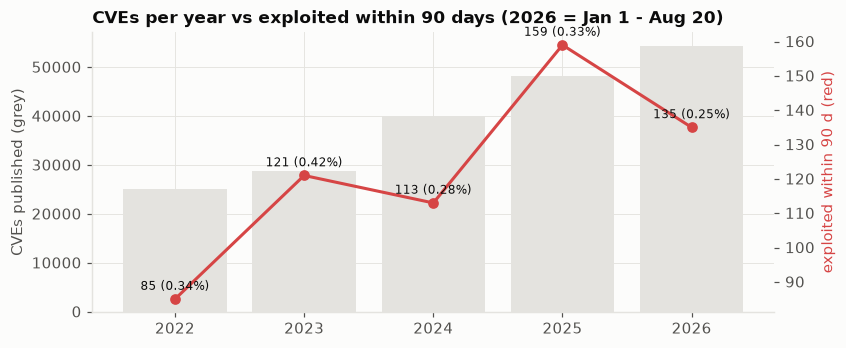

In [2]:
py = T("03_positives_by_year")
kev = pd.read_csv(sorted((ROOT / "data" / "raw").glob("kev_*.csv"))[-1])
print(f"KEV snapshot: {len(kev):,} entries, dateAdded {kev['dateAdded'].min()} -> {kev['dateAdded'].max()}, CVE years {kev['cveID'].str[4:8].min()}-{kev['cveID'].str[4:8].max()}")
print(f"dataset: {py['cves'].sum():,} CVEs (2022-01-01 -> 2026-08-20), {py['positives'].sum()} exploited within 90 days ({py['positives'].sum() / py['cves'].sum():.2%})")
display(py.set_index("year"))
fig, ax = plt.subplots(figsize=(8, 3.3)); ax2 = ax.twinx()
ax.bar(py["year"].astype(str), py["cves"], color=GRID); ax2.plot(py["year"].astype(str), py["positives"], "o-", color=RED, lw=2)
for x, (p, r) in enumerate(zip(py["positives"], py["rate_%"])): ax2.annotate(f"{p} ({r:.2f}%)", (x, p), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=8)
ax.set_ylabel("CVEs published (grey)"); ax2.set_ylabel("exploited within 90 d (red)", color=RED); ax2.grid(False)
ax.set_title("CVEs per year vs exploited within 90 days (2026 = Jan 1 - Aug 20)", loc="left"); save(fig, "1_01_problem")

**Takeaway**: **196,403 CVEs (2022 → Aug 2026), only 613 (0.31%, ~1 in 320) exploited within 90 days.** Volume doubled from 25,073 (2022) to 48,150 (2025) and 2026 is on track for ~85,000, while exploited CVEs stay in the low hundreds a year (85–159). The emergency list must stay small while the haystack grows.

## 1.2 The evolution of cybersecurity (descriptive only — no modelling choice uses this section)
NVD data cover 2022-01 → 2026-08; the KEV catalogue reaches back to CVEs from 2002 for the long view.

,CVEs,CNA CVSS >= 9 %,no CNA score,cvss_source=other %
year,,,,
2022,25073,3.7,57.4,16.3
2023,28816,4.7,39.9,20.2
2024,39953,5.4,30.2,24.6
2025,48150,5.9,24.3,18.1
2026,54411,8.9,19.4,14.6


,kev_listed,median_days,<= 0 d %,<= 7 d %,<= 30 d %,<= 90 d % (= label 1)
year,,,,,,
2022,131,24.0,29.8,38.9,51.9,64.9
2023,166,6.0,27.7,52.4,64.5,72.9
2024,161,13.0,24.8,48.4,59.0,70.2
2025,198,8.0,24.7,49.0,63.6,80.3
2026,150,7.5,24.0,50.0,71.3,90.0


share of exploited CVEs (%) by vendor ('cna:' = vendor missing):


year,2022,2023,2024,2025,2026
vendor,,,,,
microsoft,23.5,18.2,21.2,17.6,17.0
google,11.8,6.6,9.7,6.3,4.4
apple,10.6,15.7,5.3,5.0,1.5
fortinet,2.4,2.5,2.6,4.4,3.0
ivanti,0.0,2.5,7.1,4.4,3.7
cisco,7.1,3.3,3.5,3.8,9.6
adobe,1.2,3.3,0.9,1.3,2.2
cna:cve@mitre.org,12.9,11.6,7.1,1.3,0.0
cna:security@vmware.com,4.7,0.8,2.6,1.3,0.0


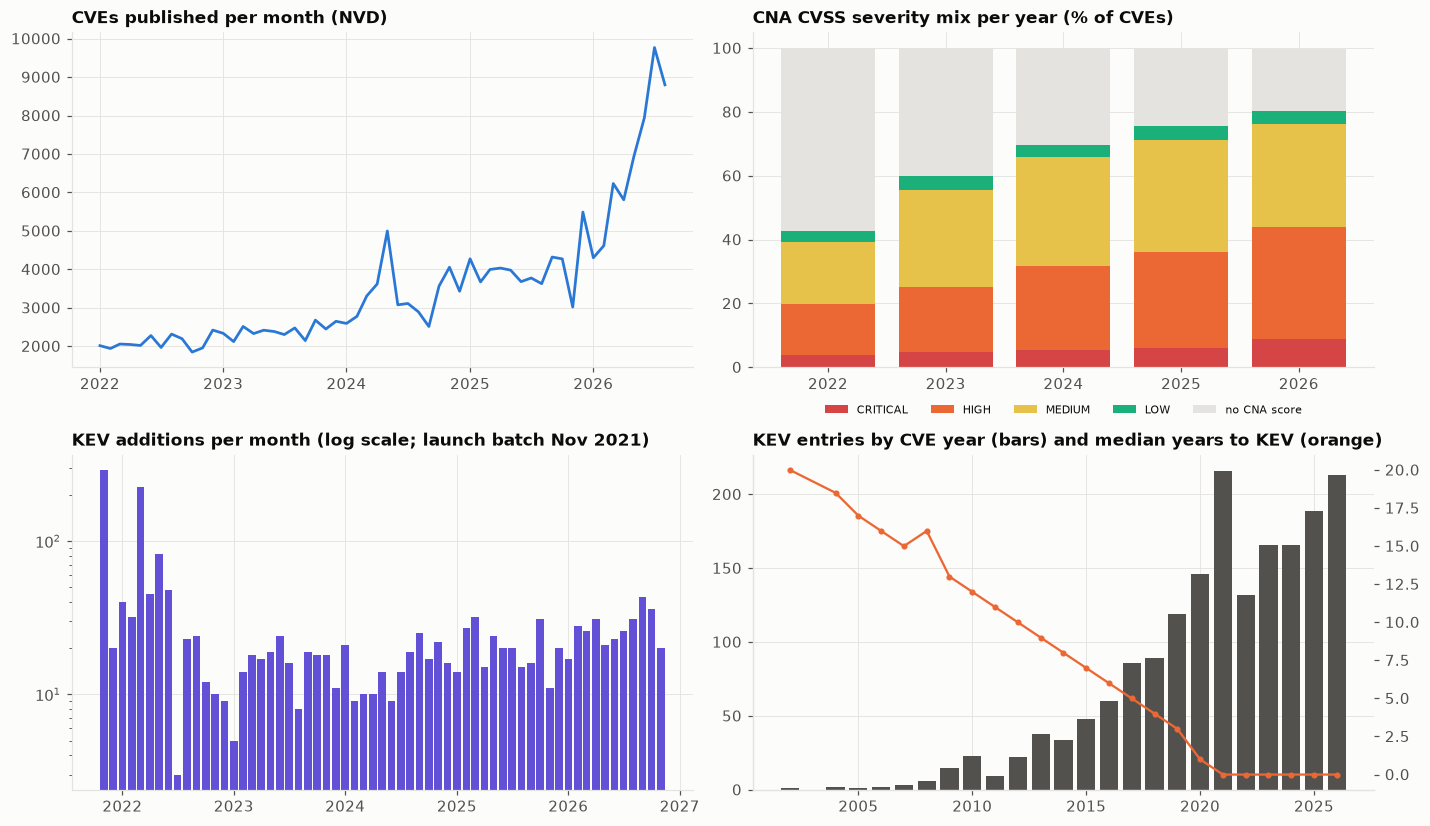

In [3]:
mo = T("00_evo_monthly"); mix = T("00_evo_cvss_mix").set_index("year"); kbm = T("00_kev_by_month"); kcy = T("00_kev_by_cve_year")
ven = T("00_evo_vendors"); dtk = T("00_evo_days_to_kev").set_index("year")
fig, axes = plt.subplots(2, 2, figsize=(13, 7.6))
a = axes[0, 0]; a.plot(pd.PeriodIndex(mo["month"], freq="M").to_timestamp(), mo["cves"], color=BLUE, lw=1.8); a.set_title("CVEs published per month (NVD)", loc="left")
a = axes[0, 1]; bottom = np.zeros(len(mix))
for s, c in zip(["CRITICAL", "HIGH", "MEDIUM", "LOW", "no CNA score"], [RED, ORANGE, "#e7c24a", AQUA, GRID]):
    a.bar(mix.index.astype(str), mix[s], bottom=bottom, color=c, label=s); bottom += mix[s].to_numpy()
a.set_title("CNA CVSS severity mix per year (% of CVEs)", loc="left"); a.legend(frameon=False, fontsize=7.5, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.08))
a = axes[1, 0]; a.bar(pd.PeriodIndex(kbm["dateAdded"], freq="M").to_timestamp(), kbm["kev_additions"], width=25, color=VIOLET); a.set_yscale("log")
a.set_title("KEV additions per month (log scale; launch batch Nov 2021)", loc="left")
a = axes[1, 1]; a.bar(kcy["cve_year"], kcy["kev_entries"], color=INK2); a2 = a.twinx(); a2.grid(False)
a2.plot(kcy["cve_year"], kcy["median_years_cve_to_kev"], "o-", color=ORANGE, ms=3); a.set_title("KEV entries by CVE year (bars) and median years to KEV (orange)", loc="left")
fig.tight_layout(); save(fig, "1_02_evolution")
display(mix[["CVEs", "CNA CVSS >= 9 %", "no CNA score", "cvss_source=other %"]].round(1)); display(dtk)
print("share of exploited CVEs (%) by vendor ('cna:' = vendor missing):"); display(ven.pivot(index="vendor", columns="year", values="share of exploited %").round(1).sort_values(2025, ascending=False))

**Takeaway**: **Volume is accelerating** (~2,100 CVEs a month in 2022 → ~6,800 in 2026). **CNAs now score most CVEs themselves** (CVEs without a CNA CVSS: 57% → 19%), and **'critical' is inflating** (CNA CVSS ≥ 9: 3.7% → 8.9% of CVEs, i.e. ~80 → ~600 patches a month under a CVSS ≥ 9 policy). **Exploitation is listed faster**: among KEV-listed CVEs, 52% (2022) vs 71% (2026) within 30 days, about a quarter on or before publication day. **KEV is now mostly about new CVEs**: CVEs from 2017 waited a median 5 years for KEV; CVEs since 2021 are listed the same year. Microsoft is consistently 17–24% of exploited CVEs; Cisco rose to 9.6% in 2026.

## 1.3 The leakage hunt
NVD returns **today's** version of each record, and some fields are added *because* a CVE was exploited. Each leak
was found in the data and fixed before modelling (decisions dated in `docs/decision_log.md`).

,evidence,fix,before -> after
leak,,,
CVSS from CISA-ADP / NVD (added after publication),2022Q1: 3.4% of CVEs vs 46.4% of exploited CVEs have an ADP score,CVSS features from the CNA's own score only,CVSS>=9 rule on train: 35.1% at 306/mo (with late scores) -> 21.9% at 110/mo (CNA only)
CWE assigned later by NVD analysts,55.4% of exploited train CVEs got their CWE from NVD,CNA CWE only,feature defined before any model was fit
descriptions edited after exploitation,edited: 30.4% of exploited vs 12.3% of other CVEs,description_day0: exploitation phrases not in the first recorded version removed,earliest vs today's text: rank correlation 0.977
vendor KEV history counting future / own entries,today's KEV includes entries added after publication,"only entries added BEFORE publication, never the CVE's own","val recall@110: guarded 47.1 / own-entry 45.6 / naive 35.0 (guarantee, no inflation here)"
random train/test split,51% of random-split val positives had an exploited same-vendor+month twin in train,split by date + walk-forward,same model: random split 59.1% vs date split 38.2%
CNA revised its own CVSS later (residual),5.5% of exploited vs 1.9% of other CVEs,not fixable from day-0 data; sensitivity run,selection score 47.4 -> 46.6 with first known vector


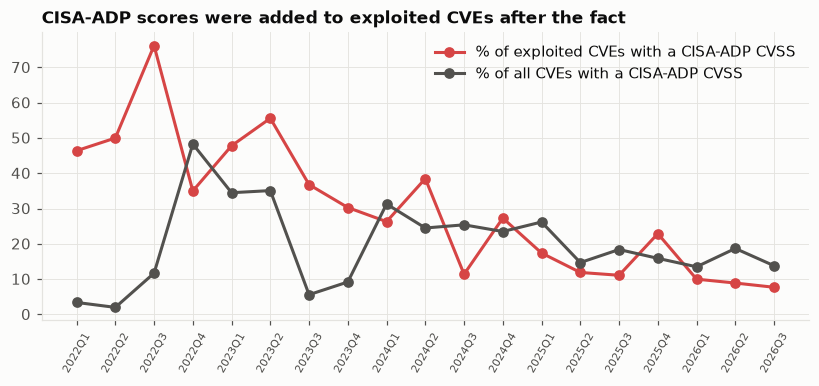

In [4]:
adp = T("00_leak_adp_by_quarter"); b = T("03b_train_baselines_cna_vs_fallback"); cwe = T("03c_train_cwe_source").set_index("cwe_fallback_source")
ed = T("03e_history_description_changes").set_index("label"); sens = T("05b_sensitivity_original_text"); kh = T("00_leak_kev_history"); rs = T("04_random_vs_date_split")
leaks = pd.DataFrame([
 {"leak": "CVSS from CISA-ADP / NVD (added after publication)", "evidence": f"2022Q1: {adp.iloc[0]['% of CVEs with ADP CVSS']:.1f}% of CVEs vs {adp.iloc[0]['% of exploited with ADP CVSS']:.1f}% of exploited CVEs have an ADP score",
  "fix": "CVSS features from the CNA's own score only", "before -> after": f"CVSS>=9 rule on train: {b.iloc[1]['recall_%']}% at {b.iloc[1]['patches/month']}/mo (with late scores) -> {b.iloc[0]['recall_%']}% at {b.iloc[0]['patches/month']}/mo (CNA only)"},
 {"leak": "CWE assigned later by NVD analysts", "evidence": f"{cwe.loc['nvd', 'share_of_pos_%']}% of exploited train CVEs got their CWE from NVD", "fix": "CNA CWE only", "before -> after": "feature defined before any model was fit"},
 {"leak": "descriptions edited after exploitation", "evidence": f"edited: {ed.loc['positives (all)', 'desc_changed_%']}% of exploited vs {ed.loc['negatives (sample)', 'desc_changed_%']}% of other CVEs",
  "fix": "description_day0: exploitation phrases not in the first recorded version removed", "before -> after": f"earliest vs today's text: rank correlation {sens.iloc[0]['Spearman (sample CVEs)']:.3f}"},
 {"leak": "vendor KEV history counting future / own entries", "evidence": "today's KEV includes entries added after publication", "fix": "only entries added BEFORE publication, never the CVE's own",
  "before -> after": f"val recall@110: guarded {kh.iloc[0]['val recall@110 %']} / own-entry {kh.iloc[1]['val recall@110 %']} / naive {kh.iloc[2]['val recall@110 %']} (guarantee, no inflation here)"},
 {"leak": "random train/test split", "evidence": f"{rs.iloc[1].iloc[-1]:.0f}% of random-split val positives had an exploited same-vendor+month twin in train", "fix": "split by date + walk-forward",
  "before -> after": f"same model: random split {rs.iloc[1]['recall@3.4% of monthly CVEs']}% vs date split {rs.iloc[0]['recall@3.4% of monthly CVEs']}%"},
 {"leak": "CNA revised its own CVSS later (residual)", "evidence": "5.5% of exploited vs 1.9% of other CVEs", "fix": "not fixable from day-0 data; sensitivity run", "before -> after": "selection score 47.4 -> 46.6 with first known vector"}]).set_index("leak")
display(leaks)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(adp["published"], adp["% of exploited with ADP CVSS"], "o-", color=RED, lw=2, label="% of exploited CVEs with a CISA-ADP CVSS")
ax.plot(adp["published"], adp["% of CVEs with ADP CVSS"], "o-", color=INK2, lw=2, label="% of all CVEs with a CISA-ADP CVSS")
ax.tick_params(axis="x", rotation=60, labelsize=7.5); ax.legend(frameon=False); ax.set_title("CISA-ADP scores were added to exploited CVEs after the fact", loc="left"); save(fig, "1_03_leak_adp")

**Takeaway**: **Five shortcuts in today's NVD/KEV data would have leaked the answer.** CISA-ADP CVSS scores were back-filled mostly for exploited CVEs (2022Q1: 46% of exploited vs 3.4% of all) and would make the CVSS ≥ 9 rule look like 35.1% recall instead of the honest 21.9%; NVD-assigned CWEs cover 55% of exploited CVEs; descriptions were edited after exploitation (30.4% vs 12.3%); vendor KEV history must stop at the publication date (guarded by design — the leaky variants did not inflate validation here, 45.6% / 35.0% vs 47.1%); and a random split inflates recall from 38.2% to 59.1%. **Residual:** CNAs later revise their own CVSS (5.5% vs 1.9%), costing 0.8 points when tested.